# 05 · Sanity checks and evaluation of the explanations
Can we trust the explanations? Three checks, following Tema 7 (fidelity ≠ plausibility, always compare with a random baseline):

1. **Label randomisation** (Adebayo et al.): a model trained on shuffled labels has learnt nothing, so its explanations should *not* look like the real ones.
2. **Feature deletion, MoRF / LeRF** (fidelity): remove the features an explanation calls most (MoRF) or least (LeRF) important; performance should drop fast for MoRF and slowly for LeRF, and always better than a random ordering.
3. **Stability** ("explanation lottery"): do explanations change with the SHAP background, the LIME seed, or the model seed?

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap, warnings, itertools
from functools import partialmethod
from tqdm import tqdm; tqdm.__init__ = partialmethod(tqdm.__init__, disable=True)
from scipy.stats import spearmanr
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
import lightgbm as lgb
from lime.lime_tabular import LimeTabularExplainer
from src.preprocess import get_splits
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
X_tr, X_va, X_te, y_tr, y_va, y_te = get_splits()
gbm = joblib.load("../models/lightgbm.joblib"); feats = list(X_tr.columns); F = len(feats)
BEST = gbm.best_iteration_
bg100 = X_tr.sample(100, random_state=0)
rng = np.random.default_rng(0)
idx5k = rng.choice(len(X_te), 5000, replace=False)           # same 5,000-row test sample as notebook 03
Xs, ys = X_te.iloc[idx5k], y_te.iloc[idx5k]
expl = shap.TreeExplainer(gbm, data=bg100, feature_perturbation="interventional", model_output="raw")
sv = expl(Xs).values
print("explained:", sv.shape)

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 20%|====                | 1019/5000 [00:11<00:42]       

 22%|====                | 1114/5000 [00:12<00:41]       

 24%|=====               | 1205/5000 [00:13<00:40]       

 26%|=====               | 1298/5000 [00:14<00:39]       

...

 93%|=================== | 4643/5000 [00:51<00:03]       

 95%|=================== | 4733/5000 [00:52<00:02]       

 96%|=================== | 4823/5000 [00:53<00:01]       

 98%|===================| 4913/5000 [00:54<00:00]       

explained: (5000, 21)


## 1. Label randomisation
Same model class and hyper-parameters, same number of trees, but trained on **shuffled labels**. Its test ROC-AUC should be ≈ 0.5.

In [2]:
y_shuf = pd.Series(np.random.default_rng(0).permutation(y_tr.values), index=y_tr.index)
params = {**gbm.get_params(), "n_estimators": BEST}
rand_model = lgb.LGBMClassifier(**params).fit(X_tr, y_shuf)
print("real model  test ROC-AUC:", round(roc_auc_score(y_te, gbm.predict_proba(X_te)[:,1]), 3))
print("random model test ROC-AUC:", round(roc_auc_score(y_te, rand_model.predict_proba(X_te)[:,1]), 3),
      "| train ROC-AUC:", round(roc_auc_score(y_shuf, rand_model.predict_proba(X_tr)[:,1]), 3), "(it memorises noise, but does not generalise)")
sv_r = shap.TreeExplainer(rand_model, data=bg100, feature_perturbation="interventional", model_output="raw")(Xs).values
imp_real, imp_rand = np.abs(sv).mean(0), np.abs(sv_r).mean(0)
print(f"mean |SHAP| (summed over features): real {imp_real.sum():.3f} vs randomised {imp_rand.sum():.3f}")
print(f"Spearman between global SHAP rankings (real vs randomised): {spearmanr(imp_real, imp_rand)[0]:.2f}")
loc = [spearmanr(np.abs(sv[i]), np.abs(sv_r[i]))[0] for i in range(1000)]
print(f"local |SHAP| rank correlation per person: mean {np.nanmean(loc):.2f}")
pi_r = permutation_importance(rand_model, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
pi_g = permutation_importance(gbm, X_va, y_va, scoring="roc_auc", n_repeats=5, random_state=0, n_jobs=-1)
print(f"sum of permutation importances: real {pi_g.importances_mean.sum():.3f} vs randomised {pi_r.importances_mean.sum():.3f}")
print(f"permutation importance range: real [{pi_g.importances_mean.min():.3f}, {pi_g.importances_mean.max():.3f}] | randomised [{pi_r.importances_mean.min():.3f}, {pi_r.importances_mean.max():.3f}]")
print("note: the randomised model's feature effects are random, but the validation labels do carry real structure, so permuting a feature can move its AUC either way (negative values); only the overall magnitude is comparable.")

real model  test ROC-AUC: 0.818


random model test ROC-AUC: 0.494 | train ROC-AUC: 0.631 (it memorises noise, but does not generalise)


 27%|=====               | 1343/5000 [00:11<00:29]       

 30%|======              | 1479/5000 [00:12<00:28]       

 32%|======              | 1611/5000 [00:13<00:27]       

...

 96%|=================== | 4781/5000 [00:37<00:01]       

 98%|===================| 4916/5000 [00:38<00:00]       

mean |SHAP| (summed over features): real 2.676 vs randomised 0.229
Spearman between global SHAP rankings (real vs randomised): 0.39


local |SHAP| rank correlation per person: mean 0.28


sum of permutation importances: real 0.171 vs randomised 0.032
permutation importance range: real [-0.000, 0.048] | randomised [-0.028, 0.031]
note: the randomised model's feature effects are random, but the validation labels do carry real structure, so permuting a feature can move its AUC either way (negative values); only the overall magnitude is comparable.


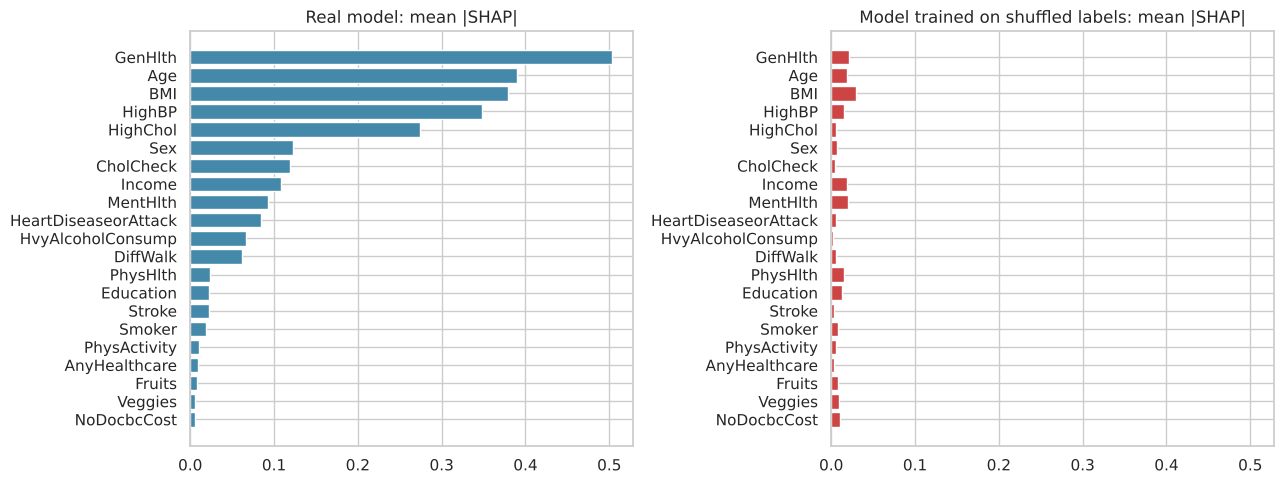

In [3]:
order = np.argsort(-imp_real)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(np.array(feats)[order][::-1], imp_real[order][::-1], color="#48a"); axes[0].set_title("Real model: mean |SHAP|")
axes[1].barh(np.array(feats)[order][::-1], imp_rand[order][::-1], color="#c44"); axes[1].set_title("Model trained on shuffled labels: mean |SHAP|")
axes[1].set_xlim(axes[0].get_xlim())
plt.tight_layout(); plt.savefig("../figures/sanity_label_randomisation.png", dpi=150); plt.show()

## 2. Feature deletion: MoRF and LeRF
For each person (5,000 test rows) we rank the features and **replace the top-k (or bottom-k) by the values of a random training person** (joint imputation, so the result stays a plausible profile; similar in spirit to ROAD, which also avoids out-of-distribution inputs). We track ROC-AUC against k, averaged over 5 random donors.
Orderings compared: **SHAP** (per person), **global permutation importance** (same order for everybody), and **random**.
Expected: MoRF-SHAP drops fastest, LeRF-SHAP slowest, random in between.

In [4]:
Xnp, tr_np = Xs.to_numpy().astype(float), X_tr.to_numpy().astype(float)
def deletion_curve(order_pos, ks=range(0, 11), n_rep=5, seed=0):
    # order_pos[i, f] = rank (0 = removed first) of feature f for person i
    r = np.random.default_rng(seed); out = np.zeros((n_rep, len(ks)))
    for rep in range(n_rep):
        donors = tr_np[r.integers(0, len(tr_np), len(Xnp))]
        for j, k in enumerate(ks):
            Xm = np.where(order_pos < k, donors, Xnp)
            out[rep, j] = roc_auc_score(ys, gbm.predict_proba(pd.DataFrame(Xm, columns=feats))[:, 1])
    return out.mean(0), out.std(0)
def to_pos(order):                       # order[i] = features sorted most -> least important
    pos = np.empty_like(order); rows = np.arange(len(order))[:, None]
    pos[rows, order] = np.arange(order.shape[1])[None, :]; return pos
ord_shap = np.argsort(-np.abs(sv), axis=1)
ord_perm = np.tile(np.argsort(-pi_g.importances_mean), (len(Xnp), 1))
ord_rand = np.argsort(np.random.default_rng(1).random((len(Xnp), F)), axis=1)
ks = list(range(0, 11)); curves = {}
for name, o in [("SHAP", ord_shap), ("global permutation", ord_perm), ("random", ord_rand)]:
    curves[f"MoRF {name}"] = deletion_curve(to_pos(o))
    if name != "global permutation" or True:
        curves[f"LeRF {name}"] = deletion_curve(to_pos(o[:, ::-1]))
res = pd.DataFrame({k: v[0] for k, v in curves.items()}, index=ks).round(3); res.index.name = "k removed"
res

,MoRF SHAP,LeRF SHAP,MoRF global permutation,LeRF global permutation,MoRF random,LeRF random
k removed,,,,,,
0,0.823,0.823,0.823,0.823,0.823,0.823
1,0.749,0.823,0.775,0.823,0.810,0.811
2,0.668,0.823,0.705,0.823,0.802,0.802
3,0.599,0.822,0.656,0.823,0.792,0.792
4,0.554,0.823,0.595,0.823,0.780,0.780
5,0.525,0.822,0.559,0.823,0.767,0.767
6,0.506,0.821,0.546,0.823,0.752,0.756
7,0.500,0.821,0.537,0.822,0.739,0.742
8,0.496,0.819,0.534,0.821,0.723,0.728


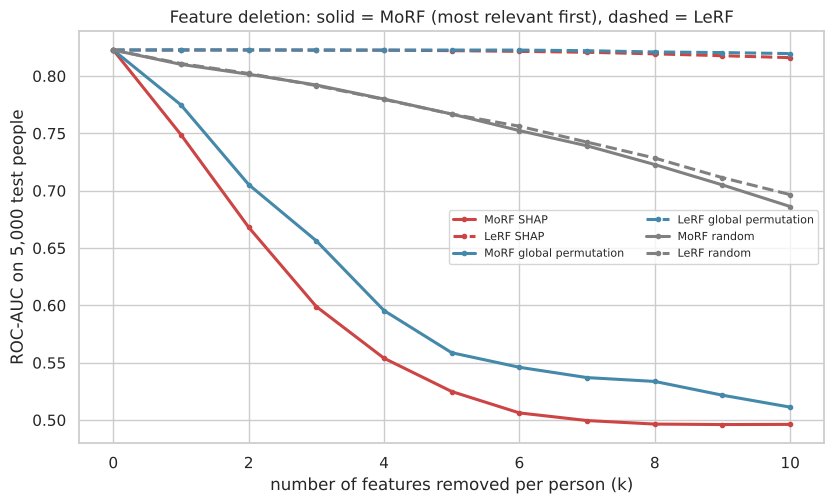

,"mean AUC, k=1..10",AUC at k=3,AUC at k=5
MoRF SHAP,0.559,0.599,0.525
LeRF SHAP,0.821,0.822,0.822
MoRF global permutation,0.594,0.656,0.559
LeRF global permutation,0.822,0.823,0.823
MoRF random,0.756,0.792,0.767
LeRF random,0.759,0.792,0.767


In [5]:
fig, ax = plt.subplots(figsize=(8.5, 5.2))
sty = {"SHAP": "#c44", "global permutation": "#48a", "random": "grey"}
for name, (m, s) in curves.items():
    kind, method = name.split(" ", 1)
    ax.plot(ks, m, c=sty[method], ls="-" if kind == "MoRF" else "--", lw=2.2, marker="o", ms=3, label=name)
ax.set_xlabel("number of features removed per person (k)"); ax.set_ylabel("ROC-AUC on 5,000 test people")
ax.set_title("Feature deletion: solid = MoRF (most relevant first), dashed = LeRF"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig("../figures/sanity_deletion.png", dpi=150); plt.show()
summ = pd.DataFrame({n: {"mean AUC, k=1..10": m[1:].mean(), "AUC at k=3": m[3], "AUC at k=5": m[5]} for n, (m, s) in curves.items()}).T.round(3)
summ

### Is LIME as faithful as SHAP? (300 people)
Same deletion idea, but with the LIME ranking, on a 300-person subset (LIME is slow). Metric: mean **absolute change of the predicted log-odds** after removing the top-3 features of each ranking (bigger = the ranking found features the model really relies on).

In [6]:
cat_idx = [i for i, f in enumerate(feats) if f not in ("BMI", "MentHlth", "PhysHlth")]
lime = LimeTabularExplainer(X_tr.to_numpy(), feature_names=feats, categorical_features=cat_idx, discretize_continuous=True, random_state=0)
def lime_w(x, seed=0):
    lime.random_state = np.random.RandomState(seed)
    e = lime.explain_instance(x, gbm.predict_proba, num_features=F, num_samples=3000, labels=(1,))
    w = dict(e.as_map()[1]); return np.array([w.get(j, 0.0) for j in range(F)])
sub = np.arange(300)                                           # first 300 of the 5,000-row sample
W = np.array([lime_w(Xnp[i], seed=i) for i in sub])
def logit_shift(order, k=3, n_rep=10):
    pos = to_pos(order[sub]); r = np.random.default_rng(0); base = gbm.predict(Xs.iloc[sub], raw_score=True); shifts = []
    for _ in range(n_rep):
        donors = tr_np[r.integers(0, len(tr_np), len(sub))]
        Xm = pd.DataFrame(np.where(pos < k, donors, Xnp[sub]), columns=feats)
        shifts.append(np.abs(gbm.predict(Xm, raw_score=True) - base).mean())
    return np.mean(shifts)
ord_lime = np.argsort(-np.abs(W), axis=1)
full_lime = np.zeros((len(Xnp), F)); full_lime[sub] = W; ord_lime_full = np.argsort(-np.abs(full_lime), axis=1)
tab = pd.Series({"SHAP": logit_shift(ord_shap), "LIME": logit_shift(ord_lime_full), "global permutation": logit_shift(ord_perm), "random": logit_shift(ord_rand)})
print("mean |change in log-odds| after removing the top-3 features (300 people):"); print(tab.round(3))

mean |change in log-odds| after removing the top-3 features (300 people):
SHAP                  1.360
LIME                  1.006
global permutation    1.238
random                0.376
dtype: float64


## 3. Stability
**(a) SHAP vs the background sample:** 5 different random backgrounds of 100 training rows, 500 people.
**(b) LIME vs its random seed:** 5 seeds, 100 people.
**(c) Model seed ("explanation lottery"):** 5 LightGBM models trained with different seeds (same hyper-parameters; they differ in the random row/column subsampling). Global SHAP ranking agreement and ROC-AUC.
Overlap measured as Jaccard of the top-5 features and Spearman of |attribution|.

In [7]:
def pair_stats(A):                                       # A: (runs, persons, features)
    j, s = [], []
    for a, b in itertools.combinations(range(A.shape[0]), 2):
        for i in range(A.shape[1]):
            ta, tb = set(np.argsort(-np.abs(A[a, i]))[:5]), set(np.argsort(-np.abs(A[b, i]))[:5])
            j.append(len(ta & tb) / len(ta | tb)); s.append(spearmanr(np.abs(A[a, i]), np.abs(A[b, i]))[0])
    return np.mean(j), np.nanmean(s)
X500 = Xs.iloc[:500]
SH = np.array([shap.TreeExplainer(gbm, data=X_tr.sample(100, random_state=s), feature_perturbation="interventional", model_output="raw")(X500).values for s in range(5)])
st_shap = pair_stats(SH)
LI = np.array([[lime_w(Xnp[i], seed=s) for i in range(100)] for s in range(5)])
st_lime = pair_stats(LI)
print(f"SHAP across backgrounds : Jaccard top-5 = {st_shap[0]:.2f}, Spearman = {st_shap[1]:.2f}")
print(f"LIME across seeds        : Jaccard top-5 = {st_lime[0]:.2f}, Spearman = {st_lime[1]:.2f}")

SHAP across backgrounds : Jaccard top-5 = 0.93, Spearman = 0.93
LIME across seeds        : Jaccard top-5 = 0.89, Spearman = 0.90


In [8]:
models, aucs, glob = [], [], []
for seed in range(5):
    m = lgb.LGBMClassifier(**{**gbm.get_params(), "n_estimators": BEST, "random_state": seed}).fit(X_tr, y_tr)
    aucs.append(roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]))
    s_ = shap.TreeExplainer(m, data=bg100, feature_perturbation="interventional", model_output="raw")(Xs.iloc[:2000]).values
    glob.append(np.abs(s_).mean(0)); models.append(m)
glob = np.array(glob)
rk = pd.DataFrame(glob.T, index=feats).rank(ascending=False)
sp = [spearmanr(glob[a], glob[b])[0] for a, b in itertools.combinations(range(5), 2)]
print("test ROC-AUC across seeds:", np.round(aucs, 4))
print(f"global SHAP ranking agreement between seeds: mean Spearman = {np.mean(sp):.3f}")
print("rank of each feature across the 5 models (min–max):")
rng_tab = pd.DataFrame({"min": rk.min(1), "max": rk.max(1)}).astype(int).assign(spread=lambda d: d["max"] - d["min"])
rng_tab.sort_values("min").head(12)

 48%|==========          | 964/2000 [00:11<00:11]       

 53%|===========         | 1055/2000 [00:12<00:10]       

 57%|===========         | 1142/2000 [00:13<00:09]       

 62%|============        | 1232/2000 [00:14<00:08]       

 66%|=============       | 1321/2000 [00:15<00:07]       

...

 88%|==================  | 1767/2000 [00:20<00:02]       

 93%|=================== | 1855/2000 [00:21<00:01]       

 97%|=================== | 1943/2000 [00:22<00:00]       

test ROC-AUC across seeds: [0.8178 0.8179 0.8177 0.818  0.8179]
global SHAP ranking agreement between seeds: mean Spearman = 0.996
rank of each feature across the 5 models (min–max):


,min,max,spread
GenHlth,1,1,0
Age,2,2,0
BMI,3,3,0
HighBP,4,4,0
HighChol,5,5,0
Sex,6,6,0
CholCheck,7,7,0
Income,8,8,0
MentHlth,9,9,0
HeartDiseaseorAttack,10,10,0


local SHAP across model seeds: Jaccard top-5 = 0.98, Spearman = 0.98


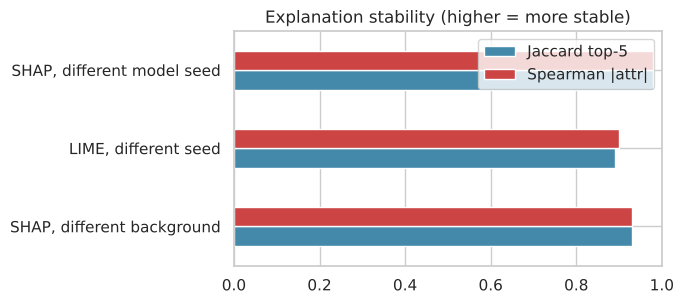

,Jaccard top-5,Spearman |attr|
"SHAP, different background",0.93,0.93
"LIME, different seed",0.89,0.90
"SHAP, different model seed",0.98,0.98


In [9]:
# local explanations of the SAME person across seeds
loc_s = np.array([shap.TreeExplainer(m, data=bg100, feature_perturbation="interventional", model_output="raw")(Xs.iloc[:300]).values for m in models])
st_seed = pair_stats(loc_s)
print(f"local SHAP across model seeds: Jaccard top-5 = {st_seed[0]:.2f}, Spearman = {st_seed[1]:.2f}")
summary = pd.DataFrame({"Jaccard top-5": [st_shap[0], st_lime[0], st_seed[0]], "Spearman |attr|": [st_shap[1], st_lime[1], st_seed[1]]},
                       index=["SHAP, different background", "LIME, different seed", "SHAP, different model seed"]).round(2)
fig, ax = plt.subplots(figsize=(7, 3.2)); summary.plot.barh(ax=ax, color=["#48a", "#c44"]); ax.set_xlim(0, 1); ax.set_title("Explanation stability (higher = more stable)")
plt.tight_layout(); plt.savefig("../figures/sanity_stability.png", dpi=150); plt.show()
summary